# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** Raisya Alayda
- **Email:** raisya7766@gmail.com
- **ID Dicoding:** ds009b6x1504

## Menentukan Pertanyaan Bisnis


**Latar belakang.** Sebuah operator sepeda berbagi (*bike sharing*) di Washington D.C. ingin mengambil keputusan operasional dan pemasaran berbasis data. Dataset yang dipakai mencakup **1 Januari 2011 – 31 Desember 2012** (731 hari / 17.379 jam pencatatan). Berikut tiga pertanyaan bisnis yang disusun dengan kerangka **SMART**:

- **Pertanyaan 1:** Pada jam berapa rata-rata penyewaan sepeda per jam mencapai puncak pada **hari kerja** dibandingkan **akhir pekan/hari libur** sepanjang 2011–2012, dan berapa selisih rata-rata penyewaan pada jam puncak tersebut, agar tim operasional dapat menjadwalkan redistribusi dan perawatan sepeda di luar jam puncak?
- **Pertanyaan 2:** Berapa persen perbedaan rata-rata penyewaan harian pada kondisi cuaca **berkabut/berawan** dan **hujan/salju ringan** dibandingkan cuaca **cerah**, serta musim apa yang memiliki rata-rata penyewaan harian tertinggi dan terendah sepanjang 2011–2012, agar tim pemasaran dapat menentukan waktu promosi dan kebijakan ukuran armada?
- **Pertanyaan 3:** Berapa persentase pertumbuhan total penyewaan tahun 2012 dibandingkan 2011 (secara keseluruhan, per bulan, serta per segmen pengguna *casual* vs *registered*), agar manajemen dapat menentukan segmen yang harus diprioritaskan pada strategi akuisisi dan retensi?

**Pemetaan SMART**

Penjelasan


**Specific** = Setiap pertanyaan fokus pada satu topik: pola jam (P1), cuaca & musim (P2), pertumbuhan tahunan & segmen pengguna (P3).

**Measurable**= Dijawab dengan angka: rata-rata penyewaan per jam, selisih jam puncak, persen perbedaan rata-rata harian, persen pertumbuhan.

**Action-Oriented** = Hasil langsung mengarah ke tindakan: jadwal redistribusi sepeda, waktu promosi/ukuran armada, prioritas segmen pengguna.

**Relevant** = Utilisasi armada, pendapatan, dan pertumbuhan pengguna adalah masalah inti bisnis bike sharing.

**Time-bound** = Seluruh analisis dibatasi pada periode 2011–2012.

## Import Semua Packages/Library yang Digunakan

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', font_scale=1.05)
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False


BLUE, ORANGE, GREY, RED = '#1f4e79', '#e08e0b', '#b8b8b8', '#c0392b'

## Data Wrangling

### Gathering Data

#### Load day_df dan hour_df

In [32]:
day_df = pd.read_csv('data/day.csv')
hour_df = pd.read_csv('data/hour.csv')

print('Ukuran day_df  :', day_df.shape)
print('Ukuran hour_df :', hour_df.shape)
day_df.head()


Ukuran day_df  : (731, 16)
Ukuran hour_df : (17379, 17)


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


In [6]:
hour_df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


**Insight:**
- day_df berisi 731 hari dan hour_df berisi 17.379 jam; keduanya memuat 2 tahun penuh (2011–2012).
- hour_df dipakai untuk analisis pola jam (Pertanyaan 1), sedangkan day_df dipakai untuk cuaca, musim, dan pertumbuhan (Pertanyaan 2 dan 3).

### Assessing Data

#### Memeriksa tipe data, missing value, dan duplikasi

In [7]:
for nama, df in [('day_df', day_df), ('hour_df', hour_df)]:
    print(f'===== {nama} =====')
    print('Total missing value :', df.isna().sum().sum())
    print('Jumlah duplikat     :', df.duplicated().sum())
    print('Tipe kolom dteday   :', df['dteday'].dtype)
    print()

day_df.info()

===== day_df =====
Total missing value : 0
Jumlah duplikat     : 0
Tipe kolom dteday   : object

===== hour_df =====
Total missing value : 0
Jumlah duplikat     : 0
Tipe kolom dteday   : object

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15

**Temuan awal:** tidak ada missing value maupun data duplikat. Namun kolom dteday bertipe teks (str/object), bukan datetime. Pemeriksaan berikutnya fokus pada nilai tidak valid, nilai tidak akurat, outlier, dan kelengkapan data.

#### Memeriksa invalid value (kelembapan = 0)

In [8]:
print('day_df  -> baris dengan hum = 0 :', (day_df['hum'] == 0).sum())
print('hour_df -> baris dengan hum = 0 :', (hour_df['hum'] == 0).sum())
print()
print('Tanggal pada day_df  :', day_df.loc[day_df['hum'] == 0, 'dteday'].tolist())
print('Tanggal pada hour_df :', hour_df.loc[hour_df['hum'] == 0, 'dteday'].unique().tolist())

# Bandingkan dengan hari-hari di sekitarnya
day_df.loc[66:70, ['dteday', 'hum', 'temp', 'weathersit', 'cnt']]

day_df  -> baris dengan hum = 0 : 1
hour_df -> baris dengan hum = 0 : 22

Tanggal pada day_df  : ['2011-03-10']
Tanggal pada hour_df : ['2011-03-10']


,dteday,hum,temp,weathersit,cnt
66,2011-03-08,0.420833,0.292500,1,2133
67,2011-03-09,0.775417,0.295833,2,1891
68,2011-03-10,0.000000,0.389091,3,623
69,2011-03-11,0.649565,0.316522,2,1977
70,2011-03-12,0.594583,0.329167,1,2132


Kelembapan udara 0% tidak masuk akal secara fisik untuk Washington D.C. pada bulan Maret. Seluruh baris bermasalah berasal dari satu hari yang sama (2011-03-10; 1 baris di day_df dan 22 jam di hour_df), sedangkan hari-hari sekitarnya bernilai 0,5–0,9. Ini adalah **invalid value** (kemungkinan sensor gagal mencatat).

#### Memeriksa inaccurate value (label musim)

In [9]:
# Rentang tanggal tiap kode musim
musim_range = day_df.groupby('season')['dteday'].agg(['min', 'max'])
print(musim_range)
print()

# Tanggal ketika kode musim berganti
day_df.loc[day_df['season'].diff() != 0, ['dteday', 'season']].head(6)

               min         max
season                        
1       2011-01-01  2012-12-31
2       2011-03-21  2012-06-20
3       2011-06-21  2012-09-22
4       2011-09-23  2012-12-20



,dteday,season
0,2011-01-01,1
79,2011-03-21,2
171,2011-06-21,3
265,2011-09-23,4
354,2011-12-21,1
445,2012-03-21,2


Readme mendefinisikan season: 1 = spring, 2 = summer, 3 = fall, 4 = winter. Padahal kode musim berganti tepat pada **titik balik musim astronomis** (21 Maret, 21 Juni, 23 September, 21 Desember). Artinya **kode 1 = Winter (21 Des – 20 Mar), 2 = Spring, 3 = Summer, 4 = Fall**. Pelabelan mengikuti Readme secara mentah akan menghasilkan kesimpulan keliru (misalnya "Spring" tampak sebagai musim terburuk). Ini adalah **label yang tidak konsisten**.

#### Memeriksa outlier

In [10]:
def hitung_outlier(series):
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    batas_bawah, batas_atas = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return ((series < batas_bawah) | (series > batas_atas)).sum(), round(batas_bawah, 3), round(batas_atas, 3)

ringkasan = []
for kolom in ['windspeed', 'casual', 'registered', 'cnt']:
    n, bb, ba = hitung_outlier(day_df[kolom])
    ringkasan.append({'kolom': kolom, 'jumlah_outlier': n, 'persen': round(n / len(day_df) * 100, 2),
                      'batas_bawah': bb, 'batas_atas': ba})
pd.DataFrame(ringkasan)

,kolom,jumlah_outlier,persen,batas_bawah,batas_atas
0,windspeed,13,1.78,-0.012,0.381
1,casual,44,6.02,-855.250,2266.750
2,registered,0,0.00,-922.250,8195.750
3,cnt,0,0.00,-1054.000,10162.000


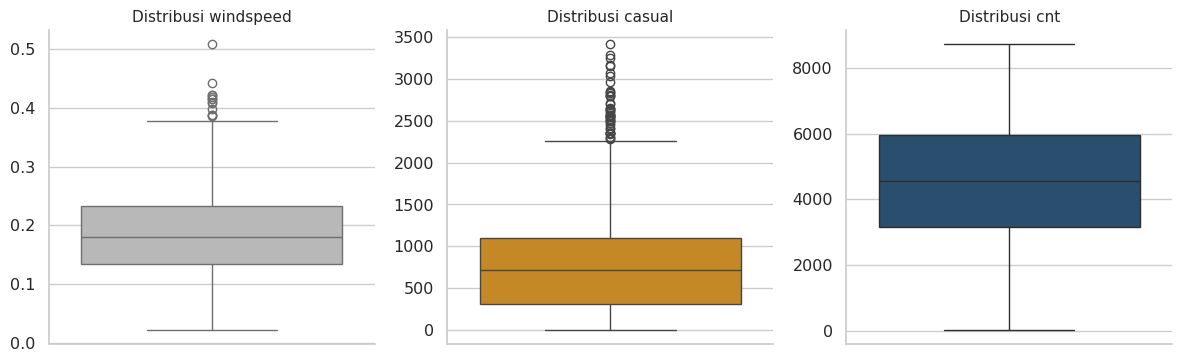

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
for ax, kolom, warna in zip(axes, ['windspeed', 'casual', 'cnt'], [GREY, ORANGE, BLUE]):
    sns.boxplot(y=day_df[kolom], ax=ax, color=warna)
    ax.set_title(f'Distribusi {kolom}', fontsize=11)
    ax.set_ylabel('')
plt.tight_layout()
plt.show()

Terdapat outlier pada `windspeed` (13 hari) dan `casual` (44 hari). Outlier `casual` hampir seluruhnya (43 dari 44 hari) terjadi pada akhir pekan/libur dengan cuaca cerah atau berkabut dan suhu sekitar 17°C, sehingga merupakan variasi nyata permintaan, bukan kesalahan pencatatan.

#### Memeriksa kelengkapan data per jam dan konsistensi total

In [12]:
jam_seharusnya = day_df.shape[0] * 24
print('Jumlah jam seharusnya :', jam_seharusnya)
print('Jumlah jam tercatat   :', hour_df.shape[0])
print('Jam tidak tercatat    :', jam_seharusnya - hour_df.shape[0])
print()
print('Baris dengan casual + registered != cnt :',
      (day_df['casual'] + day_df['registered'] != day_df['cnt']).sum(),
      '(day) /', (hour_df['casual'] + hour_df['registered'] != hour_df['cnt']).sum(), '(hour)')
print()
print('Sebaran weathersit (hour_df):')
print(hour_df['weathersit'].value_counts().sort_index())

Jumlah jam seharusnya : 17544
Jumlah jam tercatat   : 17379
Jam tidak tercatat    : 165

Baris dengan casual + registered != cnt : 0 (day) / 0 (hour)

Sebaran weathersit (hour_df):
weathersit
1    11413
2     4544
3     1419
4        3
Name: count, dtype: int64


**Steps to Take:**
- **Invalid type:** ubah `dteday` menjadi tipe *datetime* di kedua dataset.
- **Invalid value:** nilai `hum = 0` dianggap data hilang (`NaN`), lalu diisi dengan **interpolasi linear** dari jam/hari di sekitarnya.
- **Inaccurate/inconsistent value:** *relabel* `season` berdasarkan tanggal astronomis (1 = Winter, 2 = Spring, 3 = Summer, 4 = Fall), dan ubah kode numerik lain (`yr`, `mnth`, `weekday`, `weathersit`, `workingday`) menjadi label yang mudah dibaca.
- **Skala ternormalisasi:** kembalikan `temp`, `atemp`, `hum`, `windspeed` ke satuan asli (°C, %, km/jam) memakai faktor normalisasi dari Readme (41, 50, 100, 67).
- **Outlier:** `windspeed` dan `casual` **dipertahankan** karena merupakan variasi nyata; analisis akan memakai median sebagai pembanding agar tidak bias.
- **Jam tidak tercatat (165 jam):** tidak diimputasi karena analisis memakai rata-rata per jam; baris yang hilang tidak membuat bias sistematis, tetapi hal ini dicatat sebagai keterbatasan.

**Insight:**
- Kualitas dataset secara umum baik (tanpa missing value dan duplikat), tetapi terdapat **5 isu**: tipe `dteday`, kelembapan 0, label musim yang tidak akurat, outlier, dan 165 jam tidak tercatat.
- Isu label musim paling berisiko terhadap kesimpulan bisnis jika tidak ditangani.

### Cleaning Data

#### Fixing invalid type, invalid value, inaccurate label, dan skala data

In [13]:
musim_map = {1: 'Winter', 2: 'Spring', 3: 'Summer', 4: 'Fall'}   # berdasarkan titik balik musim pada data
cuaca_map = {1: 'Cerah', 2: 'Berkabut/Berawan', 3: 'Hujan/Salju Ringan', 4: 'Hujan/Salju Lebat'}
hari_map = {0: 'Minggu', 1: 'Senin', 2: 'Selasa', 3: 'Rabu', 4: 'Kamis', 5: 'Jumat', 6: 'Sabtu'}
bulan_map = {1: 'Jan', 2: 'Feb', 3: 'Mar', 4: 'Apr', 5: 'Mei', 6: 'Jun',
             7: 'Jul', 8: 'Agu', 9: 'Sep', 10: 'Okt', 11: 'Nov', 12: 'Des'}

def bersihkan(df):
    df = df.copy()
    # 1) tipe data tanggal
    df['dteday'] = pd.to_datetime(df['dteday'])
    # 2) hum = 0 dianggap hilang, lalu diinterpolasi (data sudah urut waktu)
    df['hum'] = df['hum'].replace(0, np.nan).interpolate(method='linear')
    # 3) kembalikan skala ke satuan asli
    df['temp_c'] = (df['temp'] * 41).round(2)
    df['atemp_c'] = (df['atemp'] * 50).round(2)
    df['humidity'] = (df['hum'] * 100).round(1)
    df['wind_kmh'] = (df['windspeed'] * 67).round(2)
    # 4) label kategori yang akurat dan mudah dibaca
    df['season_name'] = df['season'].map(musim_map)
    df['year'] = df['yr'].map({0: 2011, 1: 2012})
    df['month'] = df['mnth']
    df['month_name'] = df['mnth'].map(bulan_map)
    df['day_name'] = df['weekday'].map(hari_map)
    df['day_type'] = np.where(df['workingday'] == 1, 'Hari Kerja', 'Akhir Pekan/Libur')
    df['weather'] = df['weathersit'].map(cuaca_map)
    df = df.rename(columns={'cnt': 'total'})
    kolom_akhir = ['dteday', 'season_name', 'year', 'month', 'month_name', 'day_name', 'day_type',
                   'holiday', 'workingday', 'weathersit', 'weather', 'temp_c', 'atemp_c', 'humidity',
                   'wind_kmh', 'casual', 'registered', 'total']
    if 'hr' in df.columns:
        kolom_akhir.insert(3, 'hr')
    return df[kolom_akhir]

day_clean = bersihkan(day_df)
hour_clean = bersihkan(hour_df)

print('Tipe dteday      :', day_clean['dteday'].dtype)
print('Min kelembapan   :', day_clean['humidity'].min(), '(day) /', hour_clean['humidity'].min(), '(hour)')
print('Kelembapan 2011-03-10 (day):', day_clean.loc[day_clean['dteday'] == '2011-03-10', 'humidity'].values)
day_clean.head()

Tipe dteday      : datetime64[ns]
Min kelembapan   : 18.8 (day) / 8.0 (hour)
Kelembapan 2011-03-10 (day): [71.2]


,dteday,season_name,year,month,month_name,day_name,day_type,holiday,workingday,weathersit,weather,temp_c,atemp_c,humidity,wind_kmh,casual,registered,total
0,2011-01-01,Winter,2011,1,Jan,Sabtu,Akhir Pekan/Libur,0,0,2,Berkabut/Berawan,14.11,18.18,80.6,10.75,331,654,985
1,2011-01-02,Winter,2011,1,Jan,Minggu,Akhir Pekan/Libur,0,0,2,Berkabut/Berawan,14.90,17.69,69.6,16.65,131,670,801
2,2011-01-03,Winter,2011,1,Jan,Senin,Hari Kerja,0,1,1,Cerah,8.05,9.47,43.7,16.64,120,1229,1349
3,2011-01-04,Winter,2011,1,Jan,Selasa,Hari Kerja,0,1,1,Cerah,8.20,10.61,59.0,10.74,108,1454,1562
4,2011-01-05,Winter,2011,1,Jan,Rabu,Hari Kerja,0,1,1,Cerah,9.31,11.46,43.7,12.52,82,1518,1600


#### Verifikasi hasil pembersihan

In [14]:
print('Missing value day_clean  :', day_clean.isna().sum().sum())
print('Missing value hour_clean :', hour_clean.isna().sum().sum())
print()
# Pastikan label musim sesuai bulan: Winter harus mencakup Des-Mar, dst.
print(pd.crosstab(day_clean['month_name'], day_clean['season_name']).reindex(list(bulan_map.values())))

Missing value day_clean  : 0
Missing value hour_clean : 0

season_name  Fall  Spring  Summer  Winter
month_name                               
Jan             0       0       0      62
Feb             0       0       0      57
Mar             0      22       0      40
Apr             0      60       0       0
Mei             0      62       0       0
Jun             0      40      20       0
Jul             0       0      62       0
Agu             0       0      62       0
Sep            16       0      44       0
Okt            62       0       0       0
Nov            60       0       0       0
Des            40       0       0      22


In [16]:
# Simpan data bersih untuk dashboard
day_clean.to_csv('dashboard/main_data.csv', index=False)
hour_clean.to_csv('dashboard/hour_data.csv', index=False)
print('Data bersih tersimpan di folder dashboard/')

Data bersih tersimpan di folder dashboard/


**Insight:**
- Kelembapan tidak lagi bernilai 0, dan seluruh kolom bertipe sesuai (`dteday` = datetime).
- Tabel silang bulan × musim membuktikan label baru benar: Januari–Februari = Winter, Juli–Agustus = Summer, dan seterusnya (bulan Maret, Juni, September, Desember terbagi dua karena pergantian musim terjadi pada tanggal 20–23).
- Data bersih disimpan sebagai `main_data.csv` (harian) dan `hour_data.csv` (per jam) untuk dipakai dashboard.

## Exploratory Data Analysis (EDA)

### Explore statistik umum

In [17]:
day_clean[['temp_c', 'humidity', 'wind_kmh', 'casual', 'registered', 'total']].describe().round(1)

,temp_c,humidity,wind_kmh,casual,registered,total
count,731.0,731.0,731.0,731.0,731.0,731.0
mean,20.3,62.9,12.8,848.2,3656.2,4504.3
std,7.5,14.1,5.2,686.6,1560.3,1937.2
min,2.4,18.8,1.5,2.0,20.0,22.0
25%,13.8,52.1,9.0,315.5,2497.0,3152.0
50%,20.4,62.7,12.1,713.0,3662.0,4548.0
75%,26.9,73.0,15.6,1096.0,4776.5,5956.0
max,35.3,97.2,34.0,3410.0,6946.0,8714.0


In [18]:
print('Rata-rata penyewaan harian 2011 :', round(day_clean.query('year == 2011')['total'].mean()))
print('Rata-rata penyewaan harian 2012 :', round(day_clean.query('year == 2012')['total'].mean()))
print('Persentase registered terhadap total :', round(day_clean['registered'].sum() / day_clean['total'].sum() * 100, 1), '%')

# Korelasi faktor lingkungan terhadap total penyewaan harian
day_clean[['temp_c', 'humidity', 'wind_kmh', 'total']].corr()['total'].drop('total').round(2)

Rata-rata penyewaan harian 2011 : 3406
Rata-rata penyewaan harian 2012 : 5600
Persentase registered terhadap total : 81.2 %


,total
temp_c,0.63
humidity,-0.12
wind_kmh,-0.23


**Insight:**
- Rata-rata penyewaan harian sekitar 4.504, dengan rentang sangat lebar (22 hingga 8.714), sehingga faktor waktu dan cuaca jelas berpengaruh.
- Suhu berkorelasi positif cukup kuat dengan penyewaan (r ≈ 0,63), sedangkan kelembapan (r ≈ −0,12) dan kecepatan angin (r ≈ −0,23) berkorelasi negatif lemah.
- Pengguna *registered* mendominasi sekitar 81% dari total penyewaan.

### Explore Pertanyaan 1: pola penyewaan per-jam

In [19]:
pola_jam = hour_clean.groupby(['day_type', 'hr'])['total'].mean().unstack(0).round(1)

print('Jam puncak     :'); print(pola_jam.idxmax().to_string())
print('\nNilai puncak   :'); print(pola_jam.max().to_string())
print('\nTop 3 jam tersibuk per tipe hari:')
for tipe in pola_jam.columns:
    print(f'  {tipe}:', pola_jam[tipe].nlargest(3).round(0).to_dict())

pola_jam.loc[[7, 8, 9, 12, 13, 17, 18, 19]]

Jam puncak     :
day_type
Akhir Pekan/Libur    13
Hari Kerja           17

Nilai puncak   :
day_type
Akhir Pekan/Libur    372.7
Hari Kerja           525.3

Top 3 jam tersibuk per tipe hari:
  Akhir Pekan/Libur: {13: 373.0, 12: 366.0, 14: 365.0}
  Hari Kerja: {17: 525.0, 18: 492.0, 8: 477.0}


day_type,Akhir Pekan/Libur,Hari Kerja
hr,,
7,43.4,290.6
8,105.7,477.0
9,171.6,241.5
12,366.3,200.8
13,372.7,198.4
17,323.5,525.3
18,281.1,492.2
19,231.7,348.4


In [20]:
# Segmentasi waktu dalam sehari (manual grouping) dan kontribusinya terhadap total penyewaan
hour_clean['segmen_waktu'] = pd.cut(hour_clean['hr'], bins=[-1, 5, 9, 15, 19, 23],
    labels=['Dini Hari (00-05)', 'Pagi (06-09)', 'Siang (10-15)', 'Sore (16-19)', 'Malam (20-23)'])
kontribusi = hour_clean.pivot_table(index='day_type', columns='segmen_waktu', values='total', aggfunc='sum')
(kontribusi.div(kontribusi.sum(axis=1), axis=0) * 100).round(1)

segmen_waktu,Dini Hari (00-05),Pagi (06-09),Siang (10-15),Sore (16-19),Malam (20-23)
day_type,,,,,
Akhir Pekan/Libur,5.9,7.8,47.0,27.4,11.9
Hari Kerja,2.1,24.1,23.4,36.1,14.4


**Insight:**
- **Hari kerja** memiliki dua puncak komuter: **08.00 (sekitar 477 sepeda/jam)** dan puncak tertinggi **17.00 (sekitar 525 sepeda/jam)**.
- **Akhir pekan/libur** hanya memiliki satu puncak landai di siang hari, tertinggi pada **13.00 (sekitar 373 sepeda/jam)**.
- Pada 08.00 penyewaan hari kerja sekitar 4,5× akhir pekan (477 vs 106), sedangkan pada 13.00 akhir pekan justru lebih tinggi (373 vs 198).

### Explore Pertanyaan 2: pengaruh cuaca dan musim

In [21]:
urutan_cuaca = ['Cerah', 'Berkabut/Berawan', 'Hujan/Salju Ringan']
cuaca = (day_clean.groupby('weather')['total']
         .agg(rata_rata='mean', median='median', jumlah_hari='count')
         .reindex(urutan_cuaca).round(0))
cuaca['selisih_vs_cerah_%'] = ((cuaca['rata_rata'] / cuaca.loc['Cerah', 'rata_rata'] - 1) * 100).round(1)
cuaca

,rata_rata,median,jumlah_hari,selisih_vs_cerah_%
weather,,,,
Cerah,4877.0,4844.0,463,0.0
Berkabut/Berawan,4036.0,4040.0,247,-17.2
Hujan/Salju Ringan,1803.0,1817.0,21,-63.0


In [22]:
urutan_musim = ['Winter', 'Spring', 'Summer', 'Fall']
musim = (day_clean.groupby('season_name')['total']
         .agg(rata_rata='mean', median='median', jumlah_hari='count')
         .reindex(urutan_musim).round(0))
musim['selisih_vs_summer_%'] = ((musim['rata_rata'] / musim.loc['Summer', 'rata_rata'] - 1) * 100).round(1)
musim

,rata_rata,median,jumlah_hari,selisih_vs_summer_%
season_name,,,,
Winter,2604.0,2209.0,181,-53.9
Spring,4992.0,4942.0,184,-11.6
Summer,5644.0,5354.0,188,0.0
Fall,4728.0,4634.0,178,-16.2


**Insight:**
- Rata-rata penyewaan harian saat **cerah sekitar 4.877**, **berkabut/berawan sekitar 4.036 (−17,2%)**, dan **hujan/salju ringan sekitar 1.803 (−63,0%)**. Median hampir sama dengan rata-rata, jadi hasil tidak bias oleh outlier.
- Cuaca hujan/salju ringan hanya terjadi pada 21 dari 731 hari (2,9%), sehingga dampaknya besar per hari namun jarang terjadi. Kategori hujan/salju lebat tidak ada di data harian dan hanya 3 jam di data per jam.
- Musim tertinggi adalah **Summer (sekitar 5.644)** dan terendah **Winter (2.604, sekitar −54% dibanding Summer)**.

### Explore Pertanyaan 3: pertumbuhan 2012 vs 2011

In [23]:
tahunan = day_clean.groupby('year')[['casual', 'registered', 'total']].sum()
pertumbuhan_tahunan = ((tahunan.loc[2012] / tahunan.loc[2011] - 1) * 100).round(1)
print(tahunan)
print('\nPertumbuhan 2012 vs 2011 (%):'); print(pertumbuhan_tahunan.to_string())
print('\nProporsi casual 2011 :', round(tahunan.loc[2011, 'casual'] / tahunan.loc[2011, 'total'] * 100, 1), '%')
print('Proporsi casual 2012 :', round(tahunan.loc[2012, 'casual'] / tahunan.loc[2012, 'total'] * 100, 1), '%')

      casual  registered    total
year                             
2011  247252      995851  1243103
2012  372765     1676811  2049576

Pertumbuhan 2012 vs 2011 (%):
casual        50.8
registered    68.4
total         64.9

Proporsi casual 2011 : 19.9 %
Proporsi casual 2012 : 18.2 %


In [24]:
bulanan = day_clean.pivot_table(index=['month', 'month_name'], columns='year', values='total', aggfunc='sum')
bulanan['pertumbuhan_%'] = ((bulanan[2012] / bulanan[2011] - 1) * 100).round(1)
bulanan.reset_index(level=1)

year,month_name,2011,2012,pertumbuhan_%
month,,,,
1,Jan,38189,96744,153.3
2,Feb,48215,103137,113.9
3,Mar,64045,164875,157.4
4,Apr,94870,174224,83.6
5,Mei,135821,195865,44.2
6,Jun,143512,202830,41.3
7,Jul,141341,203607,44.1
8,Agu,136691,214503,56.9
9,Sep,127418,218573,71.5


In [25]:
# Perilaku casual vs registered pada hari kerja dan akhir pekan
day_clean.groupby('day_type')[['casual', 'registered']].mean().round(0)

,casual,registered
day_type,,
Akhir Pekan/Libur,1371.0,2959.0
Hari Kerja,607.0,3978.0


**Insight:**
- Total penyewaan naik dari **1,24 juta (2011) menjadi 2,05 juta (2012)**, pertumbuhan **64,9%**.
- Pengguna **registered tumbuh 68,4%**, lebih cepat dari **casual 50,8%**; porsi casual turun dari 19,9% menjadi 18,2%.
- Pertumbuhan bulanan berkisar **41% (Juni) sampai 157% (Maret)**. Pertumbuhan terbesar terjadi di awal tahun (Jan–Mar) yang pada 2011 masih rendah, sedangkan bulan puncak (Mei–Agu) tumbuh stabil sekitar 41% hingga 57%.
- Pengguna casual jauh lebih aktif di akhir pekan (sekitar 1.371/hari) dibanding hari kerja (sekitar 607/hari), sedangkan registered stabil di hari kerja (sekitar 3.978/hari).

## Visualization & Explanatory Analysis

### Pertanyaan 1: Pada jam berapa penyewaan memuncak pada hari kerja vs akhir pekan/libur, dan berapa selisihnya?

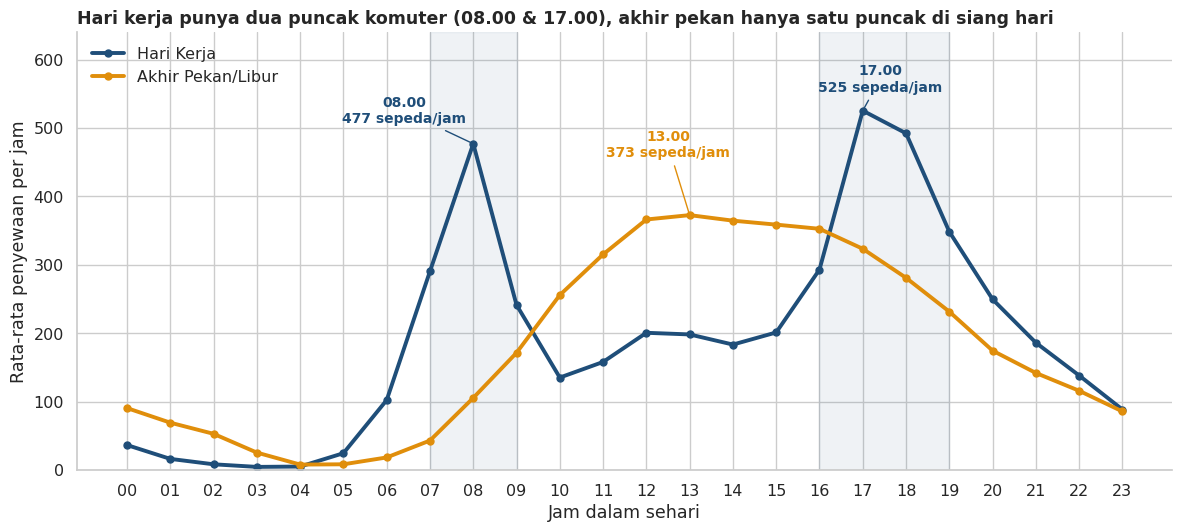

In [26]:
fig, ax = plt.subplots(figsize=(12, 5.5))
ax.axvspan(7, 9, color=BLUE, alpha=0.07)
ax.axvspan(16, 19, color=BLUE, alpha=0.07)
ax.plot(pola_jam.index, pola_jam['Hari Kerja'], color=BLUE, lw=2.8, marker='o', ms=5, label='Hari Kerja')
ax.plot(pola_jam.index, pola_jam['Akhir Pekan/Libur'], color=ORANGE, lw=2.8, marker='o', ms=5, label='Akhir Pekan/Libur')

for jam, nilai, warna, dx, dy in [(8, pola_jam.loc[8, 'Hari Kerja'], BLUE, -1.6, 30),
                                  (17, pola_jam.loc[17, 'Hari Kerja'], BLUE, 0.4, 28)]:
    ax.annotate(f'{jam:02d}.00\n{nilai:.0f} sepeda/jam', (jam, nilai), (jam + dx, nilai + dy),
                ha='center', color=warna, fontweight='bold', fontsize=10,
                arrowprops=dict(arrowstyle='-', color=warna))
jam_we = pola_jam['Akhir Pekan/Libur'].idxmax()
ax.annotate(f'{jam_we:02d}.00\n{pola_jam.loc[jam_we, "Akhir Pekan/Libur"]:.0f} sepeda/jam',
            (jam_we, pola_jam.loc[jam_we, 'Akhir Pekan/Libur']),
            (jam_we - 0.5, pola_jam.loc[jam_we, 'Akhir Pekan/Libur'] + 85),
            ha='center', color=ORANGE, fontweight='bold', fontsize=10,
            arrowprops=dict(arrowstyle='-', color=ORANGE))

ax.set_xticks(range(0, 24))
ax.set_xticklabels([f'{h:02d}' for h in range(24)])
ax.set_xlabel('Jam dalam sehari')
ax.set_ylabel('Rata-rata penyewaan per jam')
ax.set_ylim(0, 640)
ax.set_title('Hari kerja punya dua puncak komuter (08.00 & 17.00), akhir pekan hanya satu puncak di siang hari',
             loc='left', fontsize=12.5, fontweight='bold')
ax.legend(frameon=False, loc='upper left')
plt.tight_layout()
plt.show()

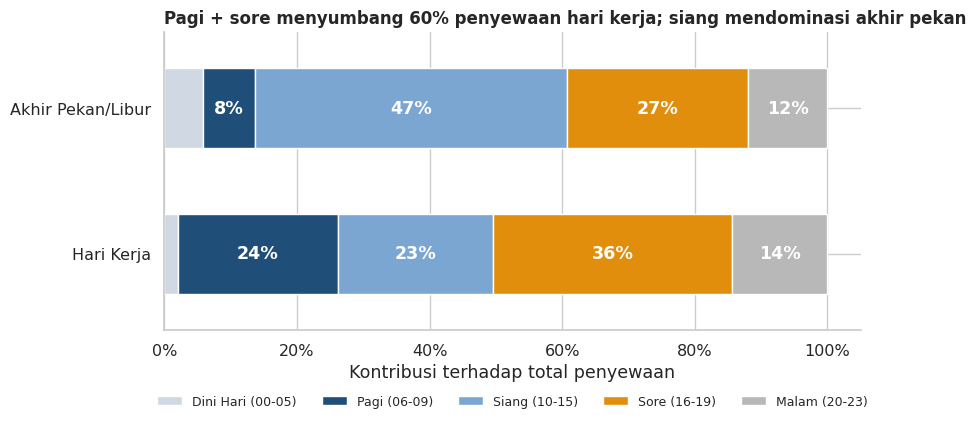

In [27]:
fig, ax = plt.subplots(figsize=(9, 4.5))
data_segmen = (kontribusi.div(kontribusi.sum(axis=1), axis=0) * 100).loc[['Hari Kerja', 'Akhir Pekan/Libur']]
data_segmen.plot(kind='barh', stacked=True, ax=ax, width=0.55,
                 color=['#cfd8e3', BLUE, '#7aa6d1', ORANGE, GREY])
for i, (idx, baris) in enumerate(data_segmen.iterrows()):
    kiri = 0
    for nilai in baris:
        if nilai > 6:
            ax.text(kiri + nilai / 2, i, f'{nilai:.0f}%', ha='center', va='center', color='white', fontweight='bold')
        kiri += nilai
ax.xaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_xlabel('Kontribusi terhadap total penyewaan')
ax.set_ylabel('')
ax.set_title('Pagi + sore menyumbang 60% penyewaan hari kerja; siang mendominasi akhir pekan',
             loc='left', fontsize=12, fontweight='bold')
ax.legend(frameon=False, ncol=5, loc='upper center', bbox_to_anchor=(0.5, -0.18), fontsize=9)
plt.tight_layout()
plt.show()

**Penjelasan Pertanyaan 1:** Pada **hari kerja** penyewaan memuncak dua kali, **08.00 (477)** dan **17.00 (525)**, mengikuti jam berangkat dan pulang kerja. Pada **akhir pekan/libur** puncaknya hanya **13.00 (373)**. Selisih puncak tertinggi: hari kerja 17.00 sekitar **41% lebih tinggi** dari puncak akhir pekan (525 vs 373). Segmen pagi (06–09) dan sore (16–19) menyumbang ±60% penyewaan hari kerja.

### Pertanyaan 2: Seberapa besar perbedaan rata-rata penyewaan harian menurut cuaca dan musim?

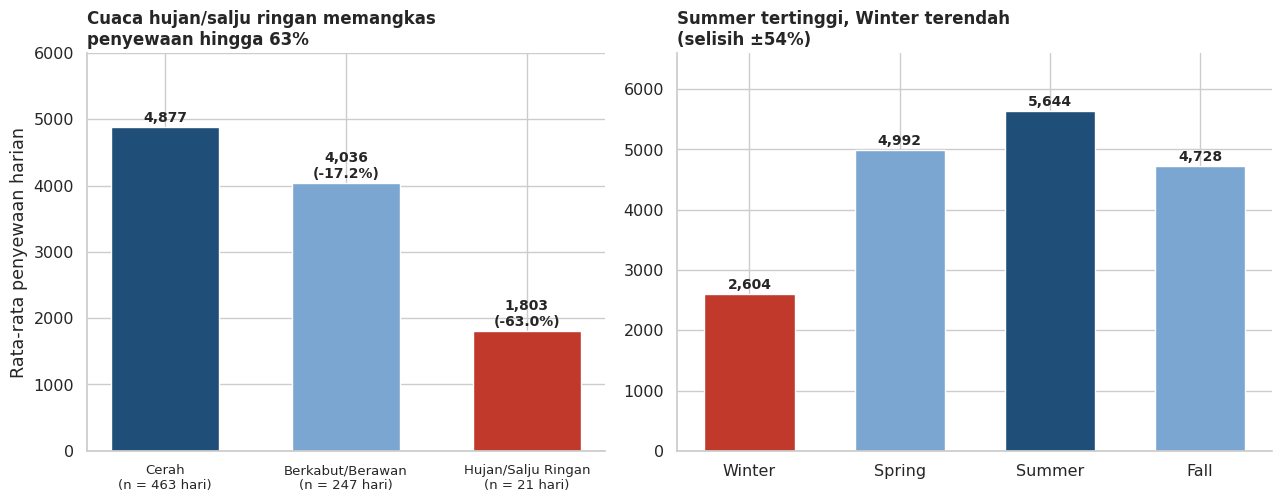

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2), gridspec_kw={'width_ratios': [1, 1.15]})

# --- Panel kiri: cuaca ---
ax = axes[0]
warna_cuaca = [BLUE, '#7aa6d1', RED]
bars = ax.bar(cuaca.index, cuaca['rata_rata'], color=warna_cuaca, width=0.6)
for bar, (nama, baris) in zip(bars, cuaca.iterrows()):
    label = f"{baris['rata_rata']:,.0f}"
    if nama != 'Cerah':
        label += f"\n({baris['selisih_vs_cerah_%']:+.1f}%)"
    ax.text(bar.get_x() + bar.get_width() / 2, baris['rata_rata'] + 80, label, ha='center', fontweight='bold', fontsize=10)
ax.set_xticklabels([f"{n}\n(n = {int(j)} hari)" for n, j in zip(cuaca.index, cuaca['jumlah_hari'])], fontsize=9.5)
ax.set_ylim(0, 6000)
ax.set_ylabel('Rata-rata penyewaan harian')
ax.set_title('Cuaca hujan/salju ringan memangkas\npenyewaan hingga 63%', loc='left', fontsize=12, fontweight='bold')

# --- Panel kanan: musim ---
ax = axes[1]
warna_musim = [RED, '#7aa6d1', BLUE, '#7aa6d1']
bars = ax.bar(musim.index, musim['rata_rata'], color=warna_musim, width=0.6)
for bar, nilai in zip(bars, musim['rata_rata']):
    ax.text(bar.get_x() + bar.get_width() / 2, nilai + 80, f'{nilai:,.0f}', ha='center', fontweight='bold', fontsize=10)
ax.set_ylim(0, 6600)
ax.set_ylabel('')
ax.set_title('Summer tertinggi, Winter terendah\n(selisih ±54%)', loc='left', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

**Penjelasan Pertanyaan 2:** Dibanding hari cerah (sekitar 4.877/hari), penyewaan turun **17,2%** saat berkabut/berawan dan **63,0%** saat hujan/salju ringan. Dari sisi musim, **Summer** tertinggi (sekitar 5.644/hari) dan **Winter** terendah (sekitar 2.604/hari), atau sekitar 54% lebih rendah. Hujan/salju ringan hanya muncul pada 21 hari (2,9%), sehingga kerugian per kejadian besar tetapi total dampak tahunannya terbatas.

### Pertanyaan 3: Berapa pertumbuhan penyewaan 2012 dibanding 2011, dan segmen mana yang tumbuh paling cepat?

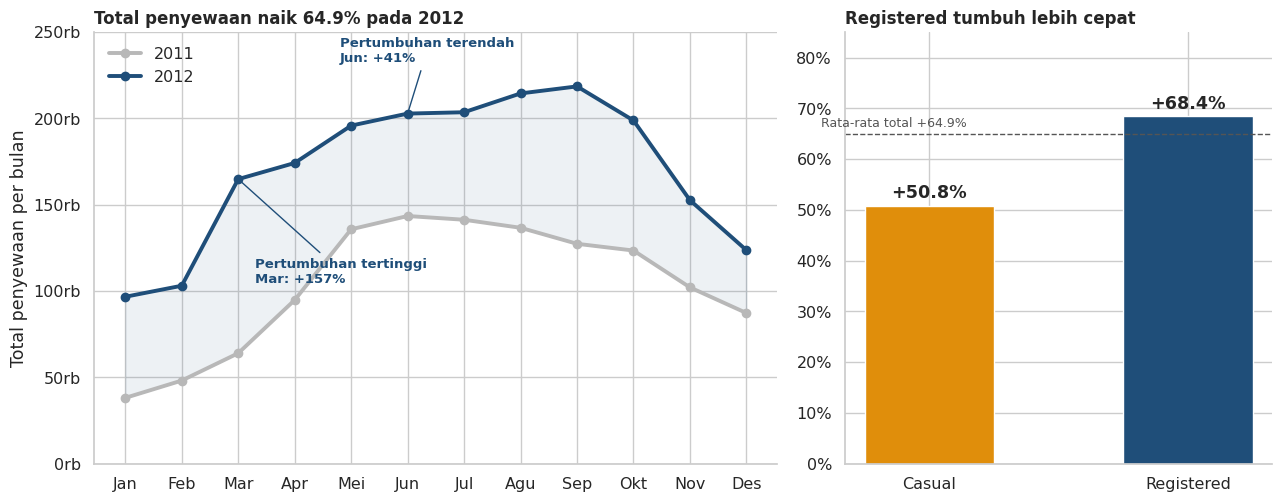

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2), gridspec_kw={'width_ratios': [1.6, 1]})

# --- Panel kiri: tren bulanan ---
ax = axes[0]
bln = bulanan.reset_index()
ax.plot(bln['month_name'], bln[2011], color=GREY, lw=2.8, marker='o', label='2011')
ax.plot(bln['month_name'], bln[2012], color=BLUE, lw=2.8, marker='o', label='2012')
ax.fill_between(bln['month_name'], bln[2011], bln[2012], color=BLUE, alpha=0.08)
idx_maks = bln['pertumbuhan_%'].idxmax()
idx_min = bln['pertumbuhan_%'].idxmin()
ax.annotate(f"Pertumbuhan tertinggi\n{bln.loc[idx_maks, 'month_name']}: +{bln.loc[idx_maks, 'pertumbuhan_%']:.0f}%",
            (idx_maks, bln.loc[idx_maks, 2012]), (idx_maks + 0.3, bln.loc[idx_maks, 2012] - 60000),
            fontsize=9.5, color=BLUE, fontweight='bold', arrowprops=dict(arrowstyle='-', color=BLUE))
ax.annotate(f"Pertumbuhan terendah\n{bln.loc[idx_min, 'month_name']}: +{bln.loc[idx_min, 'pertumbuhan_%']:.0f}%",
            (idx_min, bln.loc[idx_min, 2012]), (idx_min - 1.2, bln.loc[idx_min, 2012] + 30000),
            fontsize=9.5, color=BLUE, fontweight='bold', arrowprops=dict(arrowstyle='-', color=BLUE))
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'{x/1000:.0f}rb'))
ax.set_ylim(0, 250000)
ax.set_ylabel('Total penyewaan per bulan')
ax.set_title(f"Total penyewaan naik {pertumbuhan_tahunan['total']:.1f}% pada 2012", loc='left', fontsize=12, fontweight='bold')
ax.legend(frameon=False, loc='upper left')

# --- Panel kanan: pertumbuhan per segmen ---
ax = axes[1]
seg = pertumbuhan_tahunan[['casual', 'registered']]
bars = ax.bar(['Casual', 'Registered'], seg.values, color=[ORANGE, BLUE], width=0.5)
for bar, nilai in zip(bars, seg.values):
    ax.text(bar.get_x() + bar.get_width() / 2, nilai + 1.5, f'+{nilai:.1f}%', ha='center', fontweight='bold')
ax.axhline(pertumbuhan_tahunan['total'], color='#555555', ls='--', lw=1)
ax.text(-0.42, pertumbuhan_tahunan['total'] + 1.5, f"Rata-rata total +{pertumbuhan_tahunan['total']:.1f}%", ha='left', fontsize=9, color='#555555')
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_ylim(0, 85)
ax.set_title('Registered tumbuh lebih cepat', loc='left', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

**Penjelasan Pertanyaan 3:** Penyewaan 2012 mencapai ±2,05 juta, tumbuh **64,9%** dari sekitar 1,24 juta di 2011. Segmen **registered tumbuh +68,4%**, lebih tinggi daripada **casual +50,8%**. Pertumbuhan bulanan tertinggi terjadi di **Maret (+157%)**, terendah di **Juni (+41%)**, dan musim puncak (Mei–Agustus) tumbuh stabil di kisaran 41–57%.

**Insight:**
- Jam sibuk pada hari kerja (08.00 dan 17.00) menentukan kebutuhan ketersediaan sepeda, sedangkan akhir pekan membutuhkan stok di siang hari.
- Cuaca dan musim berpengaruh besar: penyewaan turun 17% saat berkabut, 63% saat hujan ringan, dan 54% lebih rendah di Winter dibanding Summer.
- Pertumbuhan 2012 sangat kuat (+64,9%) dan didorong terutama oleh pengguna registered.

## Analisis Lanjutan (Opsional)

Analisis lanjutan memakai **manual grouping** dan **binning** (tanpa algoritma *machine learning*), relevan karena data berisi variabel numerik kontinu (suhu, jumlah penyewaan) yang lebih mudah ditindaklanjuti bila dikelompokkan:
1. **Binning suhu** (`pd.cut`) : Dingin (< 10°C), Sejuk (10–20°C), Hangat (20–28°C), Panas (>= 28°C).
2. **Klasterisasi hari berdasarkan tingkat permintaan** (manual grouping dengan ambang bisnis): Rendah (< 3.000), Sedang (3.000–4.999), Tinggi (5.000–6.999), Sangat Tinggi (>= 7.000 penyewaan/hari).

In [30]:
# 1) Binning suhu
day_clean['kelompok_suhu'] = pd.cut(day_clean['temp_c'], bins=[-np.inf, 10, 20, 28, np.inf],
                                    labels=['Dingin (<10°C)', 'Sejuk (10-20°C)', 'Hangat (20-28°C)', 'Panas (≥28°C)'],
                                    right=False)
suhu = day_clean.groupby('kelompok_suhu')['total'].agg(rata_rata='mean', median='median', jumlah_hari='count').round(0)

# 2) Klaster hari berdasarkan tingkat permintaan
day_clean['klaster_permintaan'] = pd.cut(day_clean['total'], bins=[0, 3000, 5000, 7000, np.inf],
                                         labels=['Rendah', 'Sedang', 'Tinggi', 'Sangat Tinggi'], right=False)
klaster_musim = (pd.crosstab(day_clean['season_name'], day_clean['klaster_permintaan'], normalize='index') * 100
                 ).reindex(urutan_musim).round(1)
print(suhu, '\n')
print(day_clean['klaster_permintaan'].value_counts().reindex(['Rendah', 'Sedang', 'Tinggi', 'Sangat Tinggi']), '\n')
klaster_musim

                  rata_rata  median  jumlah_hari
kelompok_suhu                                   
Dingin (<10°C)       1678.0  1530.0           60
Sejuk (10-20°C)      3692.0  3649.0          299
Hangat (20-28°C)     5581.0  5236.0          222
Panas (≥28°C)        5661.0  5523.0          150 

klaster_permintaan
Rendah           172
Sedang           273
Tinggi           192
Sangat Tinggi     94
Name: count, dtype: int64 



klaster_permintaan,Rendah,Sedang,Tinggi,Sangat Tinggi
season_name,,,,
Winter,64.6,29.8,5.0,0.6
Spring,13.6,39.1,34.8,12.5
Summer,2.1,39.9,34.0,23.9
Fall,14.6,40.4,30.9,14.0


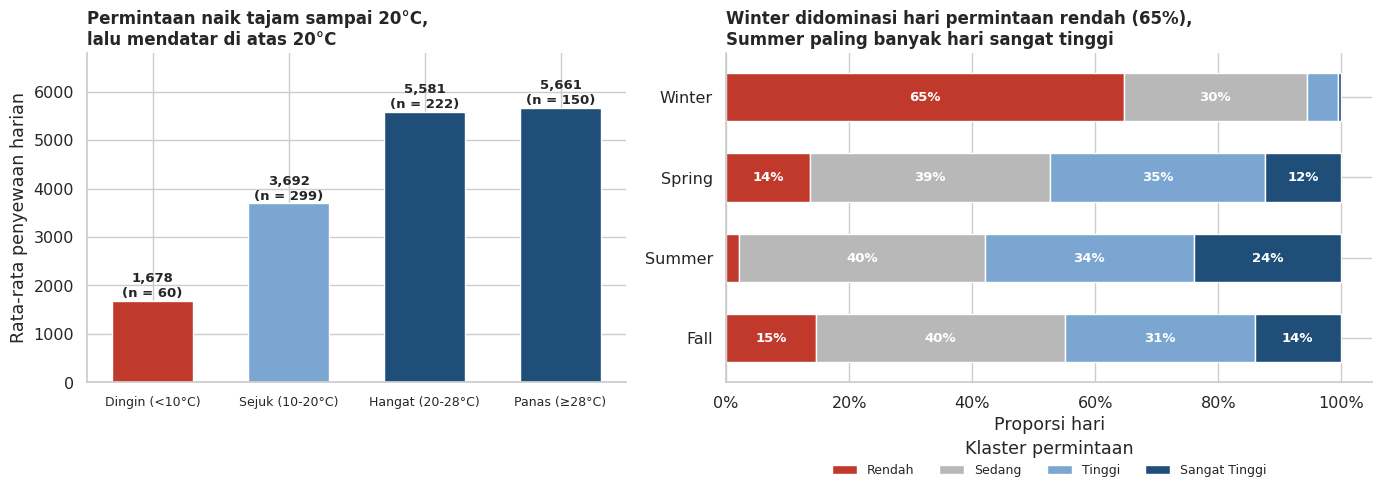

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw={'width_ratios': [1, 1.2]})

# --- Panel kiri: binning suhu ---
ax = axes[0]
warna = [RED, '#7aa6d1', BLUE, BLUE]
bars = ax.bar(suhu.index.astype(str), suhu['rata_rata'], color=warna, width=0.6)
for bar, (nama, baris) in zip(bars, suhu.iterrows()):
    ax.text(bar.get_x() + bar.get_width() / 2, baris['rata_rata'] + 80,
            f"{baris['rata_rata']:,.0f}\n(n = {int(baris['jumlah_hari'])})", ha='center', fontsize=9.5, fontweight='bold')
ax.set_ylim(0, 6800)
ax.set_ylabel('Rata-rata penyewaan harian')
ax.set_title('Permintaan naik tajam sampai 20°C,\nlalu mendatar di atas 20°C', loc='left', fontsize=12, fontweight='bold')
ax.tick_params(axis='x', labelsize=9)

# --- Panel kanan: klaster permintaan per musim ---
ax = axes[1]
klaster_musim.plot(kind='barh', stacked=True, ax=ax, width=0.6, color=[RED, GREY, '#7aa6d1', BLUE])
for i, (idx, baris) in enumerate(klaster_musim.iterrows()):
    kiri = 0
    for nilai in baris:
        if nilai >= 8:
            ax.text(kiri + nilai / 2, i, f'{nilai:.0f}%', ha='center', va='center', color='white', fontweight='bold', fontsize=9.5)
        kiri += nilai
ax.invert_yaxis()
ax.xaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_xlabel('Proporsi hari')
ax.set_ylabel('')
ax.set_title('Winter didominasi hari permintaan rendah (65%),\nSummer paling banyak hari sangat tinggi', loc='left', fontsize=12, fontweight='bold')
ax.legend(title='Klaster permintaan', frameon=False, ncol=4, loc='upper center', bbox_to_anchor=(0.5, -0.14), fontsize=9)
plt.tight_layout()
plt.show()

**Insight:**
- **Binning suhu:** rata-rata penyewaan melonjak dari 1.678 (< 10°C) ke sekitar 3.692 (10–20°C) dan 5.581 (20–28°C), lalu relatif sama di >= 28°C (5.661). Jadi kenaikan permintaan hanya terjadi sampai sekitar 20°C, dan suhu panas tidak menambah penyewaan secara berarti.
- **Klaster permintaan:** 65% hari Winter masuk klaster *Rendah* dan hampir tidak ada hari *Sangat Tinggi*, sedangkan 24% hari Summer masuk klaster *Sangat Tinggi*. Hal ini membantu perencanaan kapasitas armada per musim.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Pada hari kerja, penyewaan memuncak dua kali, pukul **08.00 (477 sepeda/jam)** dan **17.00 (525 sepeda/jam)**, mencerminkan pola komuter, dan segmen pagi + sore menyumbang 60% penyewaan harian. Pada akhir pekan/libur hanya ada satu puncak pukul **13.00 (373 sepeda/jam)**. Puncak tertinggi hari kerja (17.00) sekitar **41% lebih tinggi** daripada puncak akhir pekan; pada pukul 08.00 penyewaan hari kerja 4,5× akhir pekan.
- **Conclusion pertanyaan 2:** Dibanding cuaca cerah (4.877/hari), rata-rata penyewaan turun **17,2%** saat berkabut/berawan (4.036) dan **63,0%** saat hujan/salju ringan (1.803). **Summer** adalah musim tertinggi (5.644/hari) dan **Winter** terendah (2.604/hari, sekitar 54% lebih rendah). Hujan/salju ringan hanya terjadi pada 2,9% hari.
- **Conclusion pertanyaan 3:** Total penyewaan 2012 naik **64,9%** dibanding 2011 (1,24 juta → 2,05 juta). Pengguna **registered tumbuh +68,4%** dan **casual +50,8%**, sehingga porsi casual turun dari 19,9% menjadi 18,2%. Pertumbuhan bulanan berkisar +41% (Juni) sampai +157% (Maret). Pengguna casual jauh lebih aktif di akhir pekan (1.371/hari vs 607/hari di hari kerja).
- **Conclusion analisis lanjutan:** Permintaan naik tajam sampai suhu 20°C lalu mendatar, dan hari-hari Winter sebagian besar (65%) berada di klaster permintaan *Rendah*.

**Rekomendasi Action Item:**
- **Redistribusi sepeda terjadwal:** pada hari kerja, pastikan stok sepeda penuh di stasiun area permukiman sebelum 07.00 dan di stasiun area perkantoran sebelum 16.00; lakukan redistribusi dan perawatan di luar jam puncak (10.00–15.00 atau setelah 20.00 pada hari kerja). Pada akhir pekan, pindahkan stok ke stasiun area wisata/taman sebelum 11.00.
- **Kampanye cuaca dan musim:** jadwalkan promosi (diskon, paket langganan) pada musim rendah (Winter) dan hari berkabut untuk menopang permintaan; pada Summer fokuskan investasi pada ketersediaan armada. Terapkan notifikasi cuaca atau promo *rainy-day* untuk menekan penurunan saat hujan.
- **Konversi pengguna casual ke registered:** karena registered tumbuh lebih cepat dan stabil di hari kerja, tawarkan insentif langganan kepada pengguna casual pada akhir pekan (1.371 penyewaan/hari) melalui promo upgrade di aplikasi atau stasiun.
- **Perencanaan armada berbasis suhu:** gunakan batas 20°C sebagai sinyal; suhu di bawah 10°C diperkirakan menurunkan permintaan hingga 70% dibanding suhu hangat, sehingga armada aktif dapat dikurangi dan jadwal perawatan massal dapat dialihkan ke periode tersebut.
- **Keterbatasan:** analisis memakai data 2011–2012 satu kota, sehingga hubungan bersifat deskriptif (bukan kausal) dan perlu diperbarui dengan data terbaru sebelum dipakai sebagai target operasional.